<p style="color:#FFF; background:#06D; padding:12px; font-size:20px; font-style:italic; text-align:center">
<span style="width:49%; display:inline-block; text-align:left">Projet OUTINFO</span>
<span style="width:49%; display:inline-block; text-align:right"> </span>
<span style="font-size:40px; font-style:normal"><b>Accès aux soins</b></span><br>
<span style="width:49%; display:inline-block; text-align:left">M1 IREF</span>
<span style="width:49%; display:inline-block; text-align:right"> Décembre 2025</p>

**Binôme** : Andréa SAINT PAUL et Guillemette CIPRIANO

<h2 style="padding:16px; color:#000; background:#DDD">0. Objectif du projet</h2>


Analyser l'accès aux soins en France en combinant des données géographiques, démographiques et d'utilisation réelle des services de santé.  
Nous utilisons 5 bases de données issues de sources différentes et de formats variés pour explorer :
- Couverture SAS
- Localisation des hôpitaux
- Diagnostic d'accès aux soins urgents
- Enquête sur les hospitalisations
- Densité des médecins généralistes

Nous respectons la chaîne de traitement : Fetch → Clean → Structure → Model → Analyze → Visualize

<h2 style="padding:16px; color:#000; background:#DDD">1. Fetch</h2>

#### Imports nécessaires

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from urllib.request import urlopen
from json import loads

### **1.1. Couverture SAS (accessibilité géographique)**

*Les données utilisées proviennent du jeu « Accès aux soins : couverture territoriale par le service d’accès aux soins (SAS) » diffusé sur le site open data de l’Assurance Maladie (Ameli). Chaque enregistrement décrit un territoire (département ou région) pour une année donnée, avec notamment le taux de population couverte par un SAS et des informations géographiques (codes et libellés de département/région). Les fichiers sont fournis au format CSV, avec des colonnes séparées par des points‑virgules et des métadonnées en début de fichier, et reposent sur des données issues du SNDS et des statistiques de population de l’INSEE.*

https://data.ameli.fr/explore/dataset/couverture-sas/information/

In [2]:
url1 = 'https://data.ameli.fr/api/explore/v2.1/catalog/datasets/couverture-sas/exports/csv?use_labels=true'
df = pd.read_csv(url1, sep=';', comment='#')
df.to_csv("couverture_sas.csv", index=False)

### **1.2. Localisation des hôpitaux (points géographiques)**

*Les données utilisées proviennent du jeu « Localisation des hôpitaux dans OpenStreetMap » diffusé sur la plateforme data.gouv.fr et produit à partir d’un extrait quotidien de la base collaborative OpenStreetMap via la couche magOSM magosm:hospitals_point. Chaque enregistrement correspond à un hôpital ou établissement assimilé présent en France métropolitaine et comporte des attributs issus d’OpenStreetMap : des informations d’identification (par exemple nom de l’établissement, type d’amenity), des métadonnées OSM (identifiant, utilisateur, date de modification) et surtout des variables géographiques, avec une géométrie fournie sous forme de centroïde (coordonnées projetées) ainsi qu’une géométrie d’origine disponible au format EWKT et son type (osm_type). Ces variables permettent de recenser et localiser précisément les structures hospitalières issues d’OpenStreetMap, en vue d’analyses spatiales ou de calculs d’accessibilité territoriale.*

https://www.data.gouv.fr/datasets/localisation-des-hopitaux-dans-openstreetmap/

In [3]:
url2 = ('https://magosm.magellium.com/geoserver/wfs/?request=GetFeature&'
     'version=2.0.0&count=500000&outputFormat=csv&'
     'typeName=magosm:hospitals_point&srsName=EPSG:3857&'
     'bbox=-1809724.4405603358,4785559.799771859,'
     '2299530.2000507396,7033419.927582323')
df = pd.read_csv(url2, comment='#')
df.to_csv('hospitals_point.csv', index=False)

### **1.3. Diagnostic d'accès aux soins urgents**

*Les données proviennent du jeu « Diagnostic d'accès aux soins de médecine d’urgence au 31/12/2019 », publié par la DREES sur son portail open data (page du jeu : data.drees.solidarites-sante.gouv.fr, jeu 2943_diagnostic-d-acces-aux-soins-urgents). Chaque ligne du fichier décrit une commune de France entière et combine plusieurs types de variables : des variables administratives (codes et libellés de commune, département et région), des variables d’équipement indiquant la présence ou non d’un service d’urgences, d’un SMUR, d’un médecin correspondant SAMU ou d’un héliSMUR, et des variables de temps d’accès en minutes vers ces équipements (par exemple temps d’accès au service d’urgences ou au SMUR le plus proche). Le jeu inclut également des informations de densité de population, ce qui permet de caractériser l’accessibilité aux soins urgents en croisant offre de soins, géographie et population.*

https://data.drees.solidarites-sante.gouv.fr/explore/dataset/2943_diagnostic-d-acces-aux-soins-urgents/information/

In [4]:
url3 = ('https://data.drees.solidarites-sante.gouv.fr/api/datasets/1.0/'
     '2943_diagnostic-d-acces-aux-soins-urgents/attachments/'
     'diagnostic_d_acces_aux_soins_urgents_au_31_12_2019_xlsx')
df = pd.read_excel(url3, sheet_name='BASECOM_URGENCES_2019', header=5)
df.to_csv('acces_temps.csv', index=False, sep=';')

### **1.4. Enquête sur les hospitalisations**

*Les données utilisées proviennent du jeu « Enquête nationale sur les structures des urgences hospitalières » (volet Patient 2023), publié par la DREES sur son portail open data. Nous exploitons plus particulièrement le fichier Excel de tableaux régionaux « 2023_tableaux_regionaux_volet_patient_enquete_urgences_er_1334 », et l’onglet correspondant au tableau 6, qui décrit l’issue de la prise en charge des patients aux urgences selon la région de la structure. Chaque ligne représente une région et les variables fournissent la répartition (en pourcentage) des différents types de sorties après passage aux urgences : sortie sans hospitalisation ni UHCD, passage en unité d’hospitalisation de courte durée (UHCD), hospitalisation après UHCD, hospitalisation sans UHCD, etc. Le fichier est au format Excel et a été converti en CSV pour faciliter l’analyse statistique des taux d’hospitalisation et de sortie par région.*

https://data.drees.solidarites-sante.gouv.fr/explore/dataset/507_l-enquete-nationale-sur-les-structures-des-urgences-hospitalieres/information/

In [5]:
url4 = ('https://data.drees.solidarites-sante.gouv.fr/api/datasets/1.0/'
     '507_l-enquete-nationale-sur-les-structures-des-urgences-hospitalieres/'
     'attachments/2023_tableaux_regionaux_volet_patient_enquete_'
     'urgences_er_1334_xlsx/')
df = pd.read_excel(url4, sheet_name='Tab 6', header=3)
df.to_csv('hospitalisation.csv', index=False, sep=';')

### **1.5. Densité des médecins généralistes**

*Les données utilisées proviennent du jeu « Démographie des professionnels de santé libéraux : effectifs et densités par classe d’âge, sexe et territoire » diffusé sur la plateforme open data de l’Assurance Maladie (Ameli). Nous interrogeons ce jeu via l’API en filtrant sur l’année 2024 et sur la profession « Ensemble des médecins généralistes », et recevons les résultats au format JSON. Chaque enregistrement décrit un territoire (région ou département) et comporte des variables d’identification géographique (codes et libellés de région et de département), ainsi que des indicateurs démographiques : effectif de médecins généralistes et densité médicale pour 100 000 habitants, éventuellement ventilés par sexe ou classe d’âge. Le JSON retourné par l’API est converti en DataFrame pandas puis exporté en CSV, afin de disposer d’un fichier tabulaire structuré, prêt pour l’analyse de la répartition et de la pénurie potentielle de médecins généralistes sur le territoire.*

https://data.ameli.fr/explore/dataset/demographie-effectifs-et-les-densites/information/?disjunctive.profession_sante&disjunctive.libelle_classe_age&disjunctive.libelle_sexe&disjunctive.region&disjunctive.departement

In [6]:
url5 = ('https://data.ameli.fr/api/explore/v2.1/catalog/datasets/'
     'demographie-effectifs-et-les-densites/exports/json?lang=fr&'
     'refine=annee%3A%222024%22&refine=profession_sante%3A%22'
     'Ensemble%20des%20m%C3%A9decins%20g%C3%A9n%C3%A9ralistes%22&'
     'timezone=Europe%2FBerlin')

with urlopen(url5) as r: t = loads(r.read().decode())
df = pd.DataFrame(t)
df.to_csv('nb_medecin.csv', index=False)

<h2 style="padding:16px; color:#000; background:#DDD">2. Clean</h2>

### **2.1. Couverture SAS**

*Ce script télécharge et nettoie les données de couverture du Service d’Accès aux Soins (SAS). Pour pallier les variations fréquentes de nommage dans l'API, il applique une normalisation stricte des en-têtes et utilise une méthode de détection heuristique pour identifier la variable d'intérêt (le taux de couverture), en privilégiant la version décimale (float). Le code renomme les colonnes pour s'aligner sur le schéma du projet, filtre pour ne conserver que les données de la dernière année disponible, normalise les codes départements (format 01-95) et exporte un fichier CSV contenant uniquement les clés de jointure et l'indicateur de performance SAS.*

In [7]:
url1 = 'https://data.ameli.fr/api/explore/v2.1/catalog/datasets/couverture-sas/exports/csv'
df = pd.read_csv(url1, sep=';', comment='#')

df.columns = (df.columns.str.strip().str.lower().str.normalize('NFKD')
              .str.encode('ascii', errors='ignore').str.decode('utf-8')
              .str.replace(r'[^a-z0-9]', '_', regex=True))

c_dep = next((c for c in df.columns if 'dep' in c and 'lib' not in c), 'code_departement')

cands = [c for c in df.columns if 'taux' in c and 'couv' in c]
c_taux = next((c for c in cands if 'float' in c), cands[0] if cands else None)

if c_taux:
    df = df.rename(columns={c_dep: 'code_departement', c_taux: 'taux_sas'})
    if 'annee' in df.columns: df = df[df['annee'] == df['annee'].max()]
    df = df.dropna(subset=['code_departement', 'taux_sas'])
    df['code_departement'] = df['code_departement'].astype(str).str.zfill(2)
    df[['code_departement', 'taux_sas']].to_csv('couverture_sas_clean.csv', index=False)
else:
    pd.DataFrame(columns=['code_departement', 'taux_sas']).to_csv('couverture_sas_clean.csv', index=False)

### **2.2. Localisation des hôpitaux**

*Ce script reprend l'extraction des données hospitalières OpenStreetMap via l'URL d'origine (projection Web Mercator EPSG:3857) pour garantir la réception correcte des données. Après avoir extrait les coordonnées métriques (X, Y) du champ géométrique, le code applique une formule trigonométrique de reprojection pour convertir ces valeurs en Longitude et Latitude (degrés décimaux). Cette étape cruciale permet de générer un fichier contenant des coordonnées GPS standards, indispensables pour l'affichage ultérieur sur une carte interactive (Folium), tout en conservant les identifiants et noms des établissements.*

In [8]:
import pandas as pd
import numpy as np

url2 = ('https://magosm.magellium.com/geoserver/wfs/?request=GetFeature&'
     'version=2.0.0&count=500000&outputFormat=csv&'
     'typeName=magosm:hospitals_point&srsName=EPSG:3857&'
     'bbox=-1809724.44,4785559.80,2299530.20,7033419.93')
df = pd.read_csv(url2, comment='#')
df[['x', 'y']] = df['the_geom'].str.extract(r'POINT \(([\d\.-]+) ([\d\.-]+)\)')
df[['x', 'y']] = df[['x', 'y']].apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=['x', 'y'])
r = 6378137.0
df['longitude'] = np.degrees(df['x'] / r)
df['latitude'] = np.degrees(2 * np.arctan(np.exp(df['y'] / r)) - np.pi / 2)
rn = {'osm_id': 'identifiant', 'name': 'nom'}
df = df.rename(columns=rn)
keep = ['identifiant', 'nom', 'latitude', 'longitude']
df = df[[c for c in keep if c in df.columns]]
df.to_csv('hospitals_point_clean.csv', index=False)

### **2.3. Diagnostic d'accès aux soins urgents**

*Les données brutes du « Diagnostic d’accès aux soins urgents » (DREES) sont chargées depuis le fichier Excel en ciblant la ligne d'en-tête pertinente. Le script sélectionne et renomme les variables clés : le temps d'accès au SMUR (tps_smur), la population, ainsi que les identifiants géographiques. Le code Insee communal est impérativement conservé et normalisé (format 5 caractères) car il constitue la clé de jointure unique pour associer ultérieurement ces données médicales aux coordonnées GPS nécessaires à la cartographie. Les temps d'accès sont convertis en valeurs numériques et les entrées incomplètes sont filtrées avant l'exportation.*

In [9]:
url3 = ('https://data.drees.solidarites-sante.gouv.fr/api/datasets/1.0/'
     '2943_diagnostic-d-acces-aux-soins-urgents/attachments/'
     'diagnostic_d_acces_aux_soins_urgents_au_31_12_2019_xlsx')
df = pd.read_excel(url3, sheet_name='BASECOM_URGENCES_2019', header=5)
rn = {'Code commune Insee': 'code_insee', 'Libellé commune': 'commune',
      'Département': 'code_departement', 'Région': 'region',
      'Population 2017': 'population', 'tps_SU_SMUR': 'tps_smur'}
df = df.rename(columns=rn)
df = df[[c for c in rn.values() if c in df.columns]]
df['tps_smur'] = pd.to_numeric(df['tps_smur'], errors='coerce')
df['code_insee'] = df['code_insee'].astype(str).str.zfill(5)
df['code_departement'] = df['code_departement'].astype(str).str.zfill(2)
df = df.dropna(subset=['tps_smur', 'code_insee'])
df.to_csv('acces_temps_clean.csv', index=False)

### **2.4. Enquête sur les hospitalisations**

*Ce script standardise les données d'hospitalisation de la DREES en les convertissant du découpage historique (22 anciennes régions) vers le référentiel actuel (13 nouvelles régions). Après identification et mappage des territoires, le code effectue une agrégation par somme (groupby) sur les indicateurs numériques. Cette étape fusionne les données des anciennes régions composantes (ex: addition des chiffres de l'Aquitaine, du Limousin et du Poitou-Charentes) pour obtenir des statistiques consolidées à l'échelle de la Nouvelle-Aquitaine. La colonne des anciens noms est implicitement supprimée lors de ce regroupement, ne laissant que le code région et le nouveau libellé comme clés d'analyse.*

In [12]:
url4 = ('https://data.drees.solidarites-sante.gouv.fr/api/datasets/1.0/'
     '507_l-enquete-nationale-sur-les-structures-des-urgences-hospitalieres/'
     'attachments/2023_tableaux_regionaux_volet_patient_enquete_'
     'urgences_er_1334_xlsx/')
df = pd.read_excel(url4, sheet_name='Tab 6', header=3)
df = df.dropna(how='all', axis=1).dropna(how='all')
pat = 'Alsace|Aquitaine|Auvergne|Bourgogne|Bretagne|Centre|Corse'
c_reg = next(c for c in df.columns if df[c].astype(str).str.contains(pat).any())
df = df.rename(columns={c_reg: 'ancien_nom'})
map_new = {
    'Alsace': '44', 'Champagne-Ardenne': '44', 'Lorraine': '44',
    'Aquitaine': '75', 'Limousin': '75', 'Poitou-Charentes': '75',
    'Auvergne': '84', 'Rhône-Alpes': '84',
    'Bourgogne': '27', 'Franche-Comté': '27',
    'Languedoc-Roussillon': '76', 'Midi-Pyrénées': '76',
    'Nord-Pas-de-Calais': '32', 'Picardie': '32',
    'Basse-Normandie': '28', 'Haute-Normandie': '28',
    'Centre': '24', 'Centre-Val de Loire': '24',
    'Bretagne': '53', 'Corse': '94', 'Île-de-France': '11',
    'Pays de la Loire': '52', 'Provence-Alpes-Côte d\'Azur': '93', 'PACA': '93',
    'Guadeloupe': '01', 'Martinique': '02', 'Guyane': '03', 'La Réunion': '04'
}
df['code_region'] = df['ancien_nom'].astype(str).str.strip().map(map_new)
df = df.dropna(subset=['code_region'])
map_names = {
    '44': 'Grand Est', '75': 'Nouvelle-Aquitaine', '84': 'Auvergne-Rhône-Alpes',
    '27': 'Bourgogne-Franche-Comté', '76': 'Occitanie', '32': 'Hauts-de-France',
    '28': 'Normandie', '24': 'Centre-Val de Loire', '53': 'Bretagne',
    '94': 'Corse', '11': 'Île-de-France', '52': 'Pays de la Loire',
    '93': 'PACA', '01': 'Guadeloupe', '02': 'Martinique', '03': 'Guyane',
    '04': 'La Réunion'
}
df['nouveau_nom'] = df['code_region'].map(map_names)
cols = df.columns.difference(['ancien_nom', 'code_region', 'nouveau_nom'])
df[cols] = (df[cols].astype(str).replace({r'\u202f': '', ' ': '', ',': '.'},
            regex=True).apply(pd.to_numeric, errors='coerce'))
df = df.groupby(['code_region', 'nouveau_nom'], as_index=False)[cols].sum()
df.to_csv('hospitalisation_clean.csv', index=False)

### **2.5. Densité des médecins généralistes**

*Ce script se concentre exclusivement sur l'extraction et le nettoyage des données brutes de démographie médicale (API Ameli 2024). Après normalisation des noms de colonnes et standardisation des codes départements, il agrège les effectifs de médecins généralistes par territoire. Le fichier de sortie fournit ainsi une base saine contenant uniquement les effectifs médicaux, prête à être enrichie lors des phases ultérieures de structuration et de modélisation.*

In [13]:
import pandas as pd
from urllib.request import urlopen
from json import loads

url5 = ('https://data.ameli.fr/api/explore/v2.1/catalog/datasets/'
     'demographie-effectifs-et-les-densites/exports/json?lang=fr&'
     'refine=annee%3A%222024%22&refine=profession_sante%3A%22'
     'Ensemble%20des%20m%C3%A9decins%20g%C3%A9n%C3%A9ralistes%22&'
     'timezone=Europe%2FBerlin')

with urlopen(url5) as r: df = pd.DataFrame(loads(r.read().decode()))
df.columns = (df.columns.str.strip().str.lower().str.normalize('NFKD')
              .str.encode('ascii', errors='ignore').str.decode('utf-8')
              .str.replace(r'[^a-z0-9]', '_', regex=True))

c_dep = next((c for c in df.columns if 'dep' in c and 'lib' not in c 
              and 'reg' not in c), 'code_departement')
df = df.rename(columns={c_dep: 'code_departement', 'effectif': 'nb_medecins'})

df = df.dropna(subset=['code_departement'])
df['code_departement'] = df['code_departement'].astype(str).str.zfill(2)
df = df.groupby('code_departement', as_index=False)['nb_medecins'].sum()

df.to_csv('nb_medecin_clean.csv', index=False)

<h2 style="padding:16px; color:#000; background:#DDD">3. Structure</h2>

*Cette étape de structuration fusionne les quatre sources de données nettoyées (Urgences, SAS, Médecins, Hospitalisation) en un dataset unique centré sur la commune. Le script commence par mapper chaque département à sa région administrative (référentiel 2016) via un dictionnaire compact, créant ainsi la clé de jointure nécessaire pour les données hospitalières. Ensuite, les tableaux sont assemblés séquentiellement en prenant le fichier des temps d'accès comme base : chaque commune récupère ainsi les effectifs médicaux et le taux de couverture SAS de son département, ainsi que les indicateurs de tension hospitalière de sa région. Le fichier final dataset.csv consolide toutes ces dimensions pour l'analyse globale.*

In [15]:
dt = {'code_departement': str, 'code_insee': str, 'code_region': str}
acc = pd.read_csv('acces_temps_clean.csv', dtype=dt)
cov = pd.read_csv('couverture_sas_clean.csv', dtype=dt)
med = pd.read_csv('nb_medecin_clean.csv', dtype=dt)
hosp = pd.read_csv('hospitalisation_clean.csv', dtype=dt)

map_str = {
    '84': '01 03 07 15 26 38 42 43 63 69 73 74', '27': '21 25 39 58 70 71 89 90',
    '53': '22 29 35 56', '24': '18 28 36 37 41 45', '94': '2A 2B',
    '44': '08 10 51 52 54 55 57 67 68 88', '32': '02 59 60 62 80',
    '11': '75 77 78 91 92 93 94 95', '28': '14 27 50 61 76',
    '75': '16 17 19 23 24 33 40 47 64 79 86 87',
    '76': '09 11 12 30 31 32 34 46 48 65 66 81 82',
    '52': '44 49 53 72 85', '93': '04 05 06 13 83 84',
    '01': '971', '02': '972', '03': '973', '04': '974', '06': '976'
}
d2r = {d: r for r, s in map_str.items() for d in s.split()}

acc['code_region'] = acc['code_departement'].map(d2r)
df = acc.merge(med, on='code_departement', how='left') \
        .merge(cov, on='code_departement', how='left') \
        .merge(hosp, on='code_region', how='left')

df.to_csv('dataset.csv', index=False)

<h2 style="padding:16px; color:#000; background:#DDD">4. Model</h2>

In [16]:
import pandas as pd
import numpy as np

# Chargement du dataset structuré
df = pd.read_csv('dataset.csv', dtype={'code_departement': str, 'code_insee': str})

### **4.1. Densité Médicale**

*Nous calculons la densité médicale départementale (nombre de médecins pour 100 habitants) en rapportant les effectifs de généralistes à la population totale du département (obtenue par agrégation des populations communales). Cela crée un indicateur fiable et comparable pour mesurer l'offre de soins de ville.*

In [19]:
# On récupère la population totale par département pour le calcul
pop_dep = df.groupby('code_departement')['population'].transform('sum')
# Densité = (Nb Médecins Dept / Population Dept) * 100
df['densite_med'] = (df['nb_medecins'] / pop_dep) * 10

### **4.2. Scoring : normalisation des indicateurs entre 0 et 100**

*Afin de comparer des métriques aux unités très différentes (minutes, pourcentages, effectifs), nous transformons chaque variable en un score normalisé de 0 à 100 basé sur les rangs percentiles (rank):*
- *Score SMUR : Inversé (1 - rang), car un temps d'accès faible signifie une meilleure performance.*
- *Scores Médecins, SAS, Hôpital : Croissants, car une valeur plus élevée indique une meilleure couverture ou capacité.*

In [20]:
# Score SMUR : Plus le temps est court, meilleur est le score (1 - rank)
df['score_smur'] = (1 - df['tps_smur'].rank(pct=True)) * 100

In [21]:
# Score Médecins : Plus la densité est haute, meilleur est le score
df['score_med'] = df['densite_med'].rank(pct=True) * 100

In [22]:
# Score SAS : Plus le taux de couverture est haut, meilleur est le score
df['score_sas'] = df['taux_sas'].rank(pct=True) * 100

In [23]:
# Score Hôpital : Basé sur le taux d'hospitalisation (Capacité à accueillir)
# On suppose ici qu'un fort taux d'hospitalisation indique une bonne capacité de prise en charge
df['score_hosp'] = df['Hospitalisation'].rank(pct=True) * 100

### **4.3. Index global : pondération stratégique**

*Nous construisons un Index Global d'Accès synthétique en appliquant une moyenne pondérée aux scores précédents. La pondération reflète la criticité des soins : l'urgence vitale (SMUR, 40%) et l'accès aux soins courants (Médecins, 30%) pèsent plus lourd que la capacité d'accueil hospitalière (20%) ou le dispositif SAS (10%), offrant ainsi une vision nuancée de la qualité d'accès réelle.*

In [24]:
# On donne plus de poids à l'urgence vitale (SMUR) et à l'accès direct (Médecins)
df['index_global'] = (0.4 * df['score_smur'].fillna(0) +
                      0.3 * df['score_med'].fillna(0) +
                      0.2 * df['score_hosp'].fillna(0) +
                      0.1 * df['score_sas'].fillna(0))

### **4.4. Segmentation : classes d'accès**

*Pour faciliter l'interprétation et la visualisation cartographique, l'index continu est discrétisé en 5 classes qualitatives (quintiles) via la fonction qcut. Chaque commune est ainsi classée de « Très Mauvais » à « Excellent », permettant d'identifier immédiatement les déserts médicaux et les zones bien dotées.*

In [25]:
# Création de 5 classes (Quintiles) : Très Mauvais -> Excellent
labels = ['Très Mauvais', 'Mauvais', 'Moyen', 'Bon', 'Excellent']
df['classe_acces'] = pd.qcut(df['index_global'], 5, labels=labels)

### **4.5. Création 'dataset_scored'**

*On exporte cette nouvelle dataframe pour faire l'analyse te la visualisation par la suite.*

In [26]:
# Export final pour l'analyse et la visualisation
df.to_csv('dataset_scored.csv', index=False)

<h2 style="padding:16px; color:#000; background:#DDD">5. Analyze</h2>

*Cette étape exploite les scores calculés précédemment pour produire des statistiques descriptives et identifier les tendances territoriales. Elle ne modifie plus les données, mais extrait de la connaissance (tables récapitulatives, corrélations, classements).*

In [27]:
# Chargement du dataset scoré
df = pd.read_csv('dataset_scored.csv')

### 5.1. Statistiques globales

*Nous commençons par générer une vision macroscopique du jeu de données via la méthode describe(). Cela permet d'obtenir la moyenne, la médiane et la dispersion (écart-type) des indicateurs clés (Temps d'accès SMUR, Densité médicale, Index Global). Ce tableau de bord initial sert de référence (baseline) pour juger si une commune ou un département se situe au-dessus ou en dessous de la norme nationale.*

In [28]:
# Résumé statistique des indicateurs clés (Moyenne, Médiane, Écart-type)
cols_stats = ['tps_smur', 'densite_med', 'index_global']
stats = df[cols_stats].describe().round(2)
stats.to_csv('analyse_stats_globales.csv')
stats

,tps_smur,densite_med,index_global
count,34987.00,34870.00,34987.00
mean,23.30,0.03,48.27
std,11.78,0.01,16.15
min,0.00,0.02,0.00
25%,15.00,0.03,36.59
50%,22.00,0.03,47.36
75%,29.50,0.04,59.79
max,163.00,0.05,93.31


***Interprétation***

*L'analyse des statistiques descriptives révèle les tendances suivantes sur les 35 000 communes :*
- *Temps d'accès SMUR : La moyenne nationale s'établit à 23,3 minutes. Si la moitié des communes (médiane) sont situées à moins de 22 minutes d'un SMUR, on note une forte disparité avec un maximum atteignant 163 minutes (plus de 2h40), soulignant l'isolement critique de certains territoires.*
- *Densité médicale : Elle est en moyenne de 0,03 médecins pour 100 habitants. L'écart-type très faible (0,01) suggère que la pénurie ou la faible densité est une réalité partagée par une très grande majorité du territoire, avec peu de zones en "sur-densité".*
- *Index Global : Le score moyen d'accès aux soins est de 48,27 / 100. La proximité entre la moyenne et la médiane (47,36) indique une distribution relativement équilibrée : il n'y a pas de distorsion majeure causée par quelques communes "privilégiées".*

### 5.2. Analyse régionale (Performance moyenne par région)

*Cette étape agrège les données au niveau des Nouvelles Régions pour identifier les grandes tendances territoriales. En calculant la moyenne de l'Index Global et des sous-indicateurs par région, nous établissons un classement de performance. Cela permet de répondre à des questions politiques clés : quelle région offre le meilleur maillage sanitaire ? Les régions rurales sont-elles systématiquement défavorisées par rapport aux régions très urbanisées comme l'Île-de-France ?*

In [41]:
# On regroupe par région pour voir qui s'en sort le mieux
# 'nouveau_nom' est le libellé de la région (ex: Grand Est)
reg_perf = df.groupby('nouveau_nom')[['index_global', 'tps_smur', 'densite_med']].mean()
reg_perf = reg_perf.sort_values('index_global', ascending=False).round(2)
reg_perf.to_csv('analyse_performances_regionales.csv')
reg_perf

,index_global,tps_smur,densite_med
nouveau_nom,,,
Nouvelle-Aquitaine,61.24,23.94,0.36
Bretagne,58.95,21.12,0.37
Auvergne-Rhône-Alpes,57.56,24.90,0.34
Grand Est,50.99,22.72,0.32
PACA,48.65,30.22,0.42
Corse,47.64,43.50,0.38
Hauts-de-France,46.46,19.35,0.30
Bourgogne-Franche-Comté,45.09,25.49,0.31
Pays de la Loire,44.14,21.19,0.28


***Interprétation***

*Le classement régional met en lumière une fracture Nord/Sud et Est/Ouest inattendue :*
- *Les bons élèves : La Nouvelle-Aquitaine (61,24) et la Bretagne (58,95) dominent le classement. Elles bénéficient d'un maillage territorial efficace, combinant des temps d'accès aux urgences corrects et une densité médicale au-dessus de la moyenne.*
- *Le paradoxe PACA : La région PACA présente la plus forte densité médicale (0,42), mais se classe seulement 5ème avec un score moyen de 48,65. Cela s'explique par un temps d'accès SMUR moyen très élevé (30,22 min, le pire après la Corse), reflétant probablement les difficultés d'accès dans l'arrière-pays montagneux malgré une côte très médicalisée.*
- *L'Occitanie ferme la marche (42,49). Malgré une densité médicale correcte (0,35), elle est pénalisée par des temps d'accès aux urgences longs (26,82 min), typiques des vastes zones rurales de la région.*

### 5.3. Matrice de corrélation

$$
\underline{\text{Formule}} : \text{corrélation entre deux variables quelconques } x \text{ et } y
$$

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}
$$

*Nous calculons la matrice de corrélation de Pearson pour comprendre les interactions entre les différentes dimensions de l'accès aux soins. L'objectif est de détecter des liens statistiques : par exemple, existe-t-il une corrélation entre une faible densité médicale (désert médical) et un temps d'accès aux urgences élevé ? L'Index Global est-il davantage tiré par l'offre hospitalière ou par la médecine de ville ?*

In [43]:
# Vérifier les liens entre les variables (Ex: Densité médicale vs Temps d'accès)
# Une corrélation négative forte entre densite_med et tps_smur serait logique
corr = df[['tps_smur', 'densite_med', 'taux_sas', 'Hospitalisation', 'index_global']].corr().round(2)
corr.to_csv('analyse_correlations.csv')
corr

,tps_smur,densite_med,taux_sas,Hospitalisation,index_global
tps_smur,1.00,0.07,0.05,-0.02,-0.59
densite_med,0.07,1.00,0.19,0.12,0.62
taux_sas,0.05,0.19,1.00,0.04,0.18
Hospitalisation,-0.02,0.12,0.04,1.00,0.37
index_global,-0.59,0.62,0.18,0.37,1.00


***Interprétation***

*La matrice de corrélation nous permet de valider la cohérence de notre Index Global :*
- *Index vs SMUR (-0,59) : Il existe une forte corrélation négative. C'est logique et rassurant pour notre modèle : plus le temps d'accès aux urgences augmente (s'éloigne de 0), plus le score global diminue. Le SMUR est un déterminant structurel fort de l'accès aux soins.*
- *Index vs Densité Médicale (+0,62) : Il existe une forte corrélation positive. Plus il y a de médecins, meilleur est le score. C'est le facteur qui "tire" le plus l'index vers le haut.*
- *SMUR vs Densité Médicale (0,07) : C'est le point le plus intéressant. La corrélation est proche de zéro. Cela signifie que ces deux variables sont indépendantes : les territoires bien dotés en médecins ne sont pas nécessairement ceux qui sont proches des urgences, et inversement. L'offre de soins de ville et l'offre hospitalière d'urgence ne se superposent pas, elles obéissent à des logiques d'implantation différentes.*

### 5.4. Disparités départementales

*Enfin, nous descendons à un niveau de granularité plus fin pour mettre en lumière les inégalités territoriales extrêmes. En classant les départements selon leur score moyen, nous isolons les 5 départements les mieux dotés (« Top ») et les 5 les plus en difficulté (« Flop »). Cette liste ciblée est essentielle pour orienter les décisions publiques et prioriser les zones nécessitant une intervention urgente (installation de médecins, réorganisation des SMUR).*

In [44]:
# Identification des 5 meilleurs  départements selon l'Index Global 5 pires départements selon l'Index Global
dep_score = df.groupby('code_departement')['index_global'].mean().sort_values(ascending=False)
top_5 = dep_score.head(5)
top_5

code_departement
33    77.424843
17    76.235582
73    74.240619
64    71.971337
40    71.333156
Name: index_global, dtype: float64

In [43]:
# Identification des 5 pires  départements selon l'Index Global
dep_score = df.groupby('code_departement')['index_global'].mean().sort_values(ascending=False)
flop_5 = dep_score.tail(5)
flop_5

code_departement
48    20.330541
36    19.759680
9F    18.291708
9C    17.482608
9B    16.553913
Name: index_global, dtype: float64

***Interprétation***

*TOP 5 : le haut du classement confirme la domination absolue de la région Nouvelle-Aquitaine (identifiée comme la meilleure région dans notre analyse précédente), qui place 4 départements sur 5 en tête.*
- *33 : Gironde*
- *17 : Charente-Maritime*
- *73 : Savoie (seule exception hors Nouvelle-Aquitaine, probablement lié à une forte densité d'infrastructures due au tourisme hivernal)*
- *64 : Pyrénées-Atlantiques*
- *40 : Landes*

*FLOP 5 : le bas du classement illustre la fracture entre la "France du vide" (hyper-ruralité) et certains territoires spécifiques (codes en 9X).*
- *48 : Lozère (département le moins peuplé de France, archétype du désert médical et de l'isolement géographique)*
- *36 : Indre (zone rurale actuellement en grande difficulté démographique et médicale)*
- *9F / 9C / 9B : codes spécifiques aux territoires d'Outre-Mer*

<h2 style="padding:16px; color:#000; background:#DDD">6. Visualize</h2>

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster, HeatMap
import requests
from IPython.display import display

# chargement et configuration
df = pd.read_csv('dataset_scored.csv', dtype={'code_insee': str})
hop = pd.read_csv('hospitals_point_clean.csv')

# Style graphique
sns.set_theme(style="whitegrid")

### 6.1. Visualisation statistique

#### 6.1.1. Distribution (Histogramme)

Text(0, 0.5, 'Nombre de Communes')

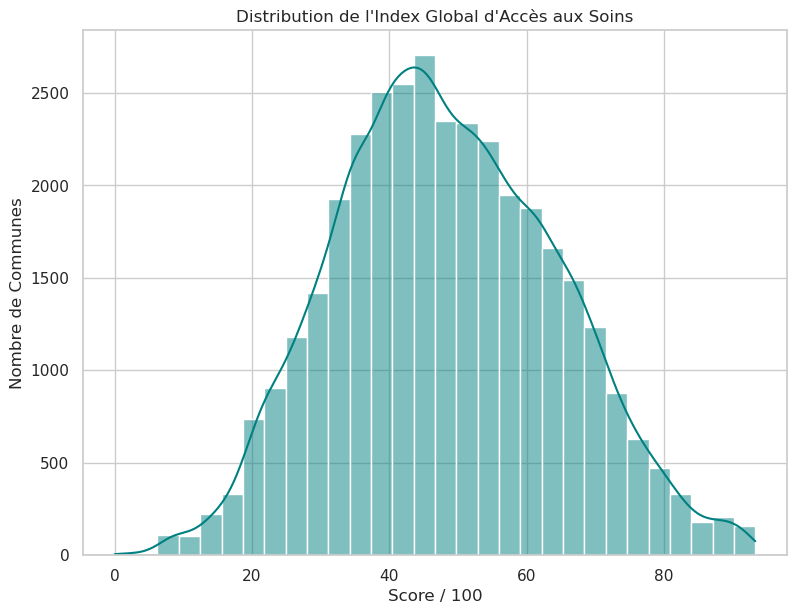

In [31]:
plt.figure(figsize=(20, 15))

# Histogramme
plt.subplot(2, 2, 1)
sns.histplot(df['index_global'], bins=30, kde=True, color='teal')
plt.title("Distribution de l'Index Global d'Accès aux Soins")
plt.xlabel("Score / 100")
plt.ylabel("Nombre de Communes")

***Interprétation***

*Ce graphique montre comment les notes d'accès aux soins sont réparties entre les 35 000 communes :*
- *Une majorité dans la moyenne : Le sommet de la courbe se situe au milieu (autour de 48/100). Cela signifie que la plupart des communes françaises ont un accès aux soins "moyen" (ni excellent, ni catastrophique).*
- *Peu d'extrêmes : La courbe descend vite sur les côtés. Il y a finalement assez peu de villes avec un score très faible (gros déserts médicaux) ou très élevé (grandes villes très équipées).*

*Notre notation est donc équilibrée. Elle ne met pas tout le monde à 0 ou à 100, ce qui permet de bien voir les différences entre les territoires.*

#### 6.1.2. Disparités régionales (Boxplot)

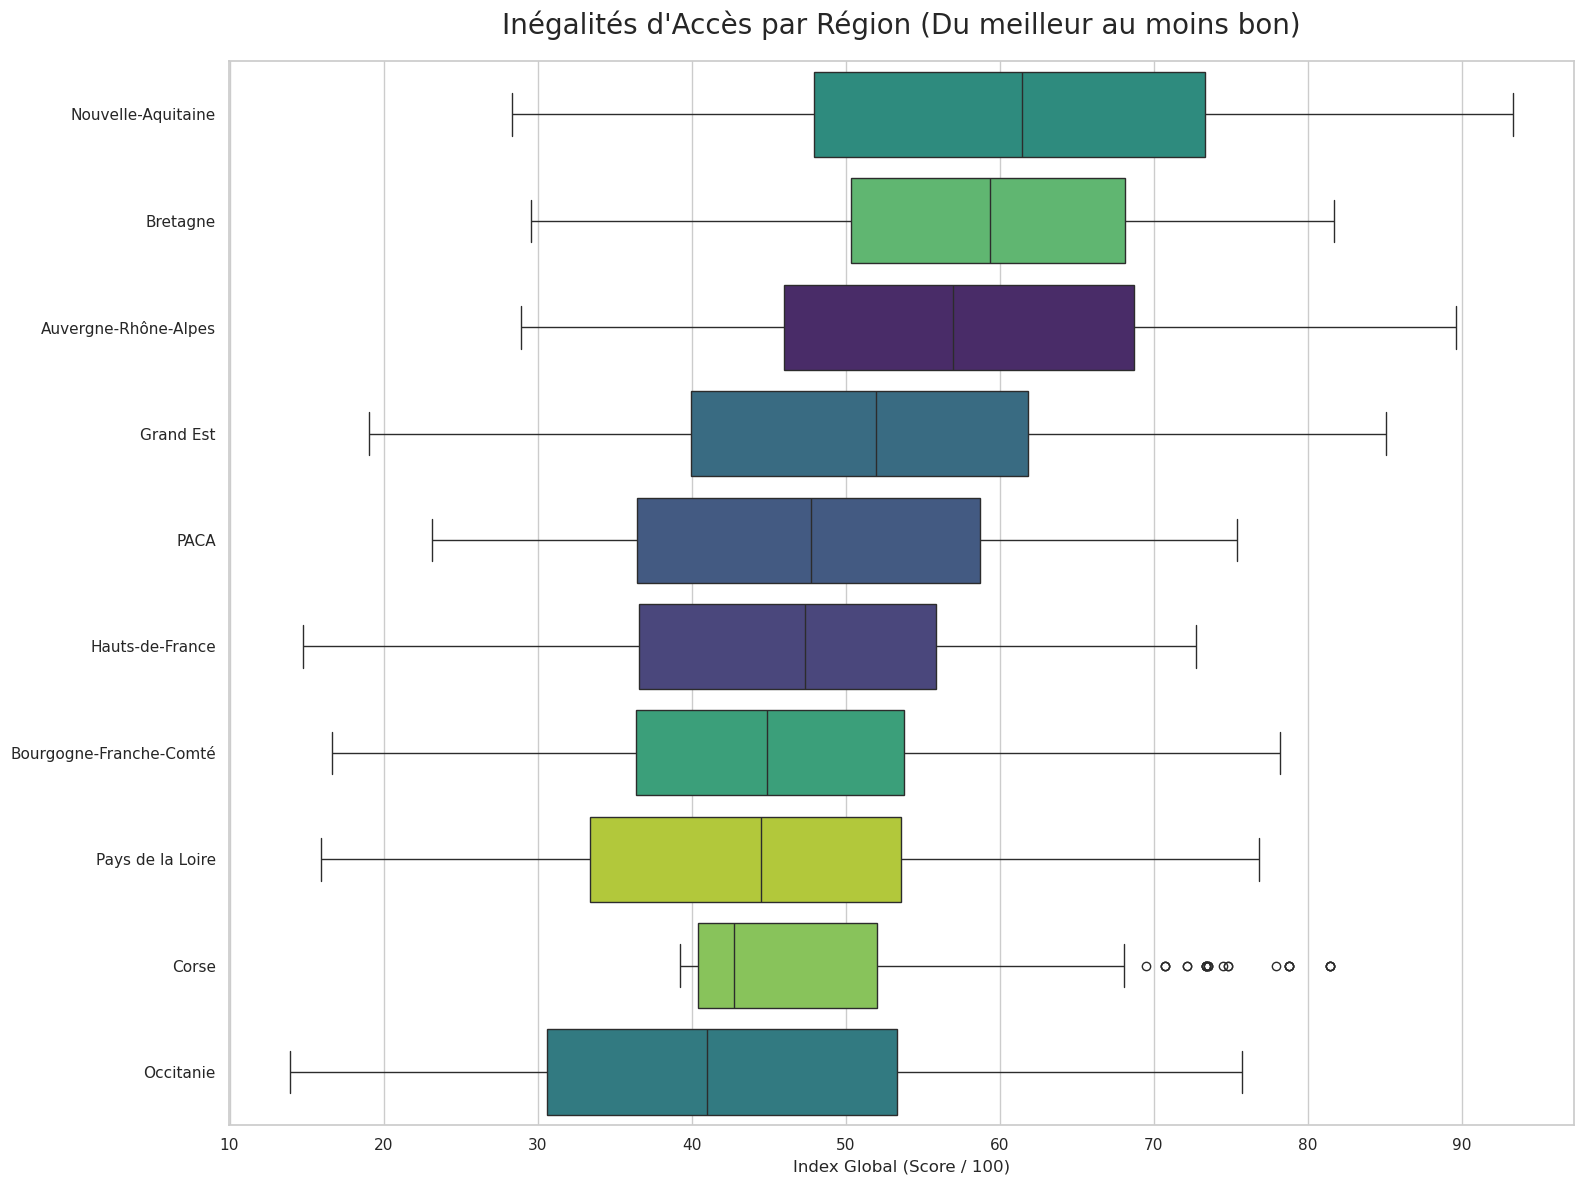

In [32]:
# 2. Disparités régionales (Boxplot) 
plt.figure(figsize=(16, 12)) 
order = df.groupby('nouveau_nom')['index_global'].median().sort_values(ascending=False).index

sns.boxplot(x='index_global', y='nouveau_nom', hue='nouveau_nom', 
            data=df, order=order, palette="viridis", legend=False)

plt.title("Inégalités d'Accès par Région (Du meilleur au moins bon)", fontsize=20, pad=20)
plt.xlabel("Index Global (Score / 100)")
plt.ylabel("")
plt.tight_layout()
plt.show()

***Interprétation***

*L'analyse de la forme des boîtes à moustaches par région révèle trois niveaux d'information :*
1. *La Médiane (Le niveau standard) : On observe un net décalage vers la droite pour la Nouvelle-Aquitaine et la Bretagne. Leur trait médian élevé (supérieur à 55) confirme que l'accès aux soins "standard" y est nettement meilleur que dans le reste de la France. À l'opposé, l'Occitanie voit sa médiane décalée vers la gauche (autour de 40), illustrant une norme d'accès structurellement plus faible pour ses habitants.*
2. *L'Homogénéité (La largeur de la boîte) : La région PACA présente une boîte particulièrement "étirée" (large). C'est le signe d'une forte hétérogénéité territoriale : elle abrite à la fois des zones très bien dotées (la côte, tirant le score vers le haut) et des zones très déficitaires (l'arrière-pays alpin). La fracture médicale y est interne. À l'inverse, des régions comme les Hauts-de-France semblent présenter des boîtes plus compactes, signe d'une situation plus homogène (même si moins favorable en moyenne).*
3. *Les Moustaches (Les extrêmes) : Le fait marquant est la longueur de la "moustache gauche" (vers les scores faibles) présente dans toutes les régions, même les plus performantes comme la Nouvelle-Aquitaine. Cela prouve qu'aucune région n'est épargnée par les déserts médicaux : il existe partout des communes "décrochées" du système de soins, situées aux extrémités basses de la distribution.*

#### 6.1.4. Relations densité / urgences

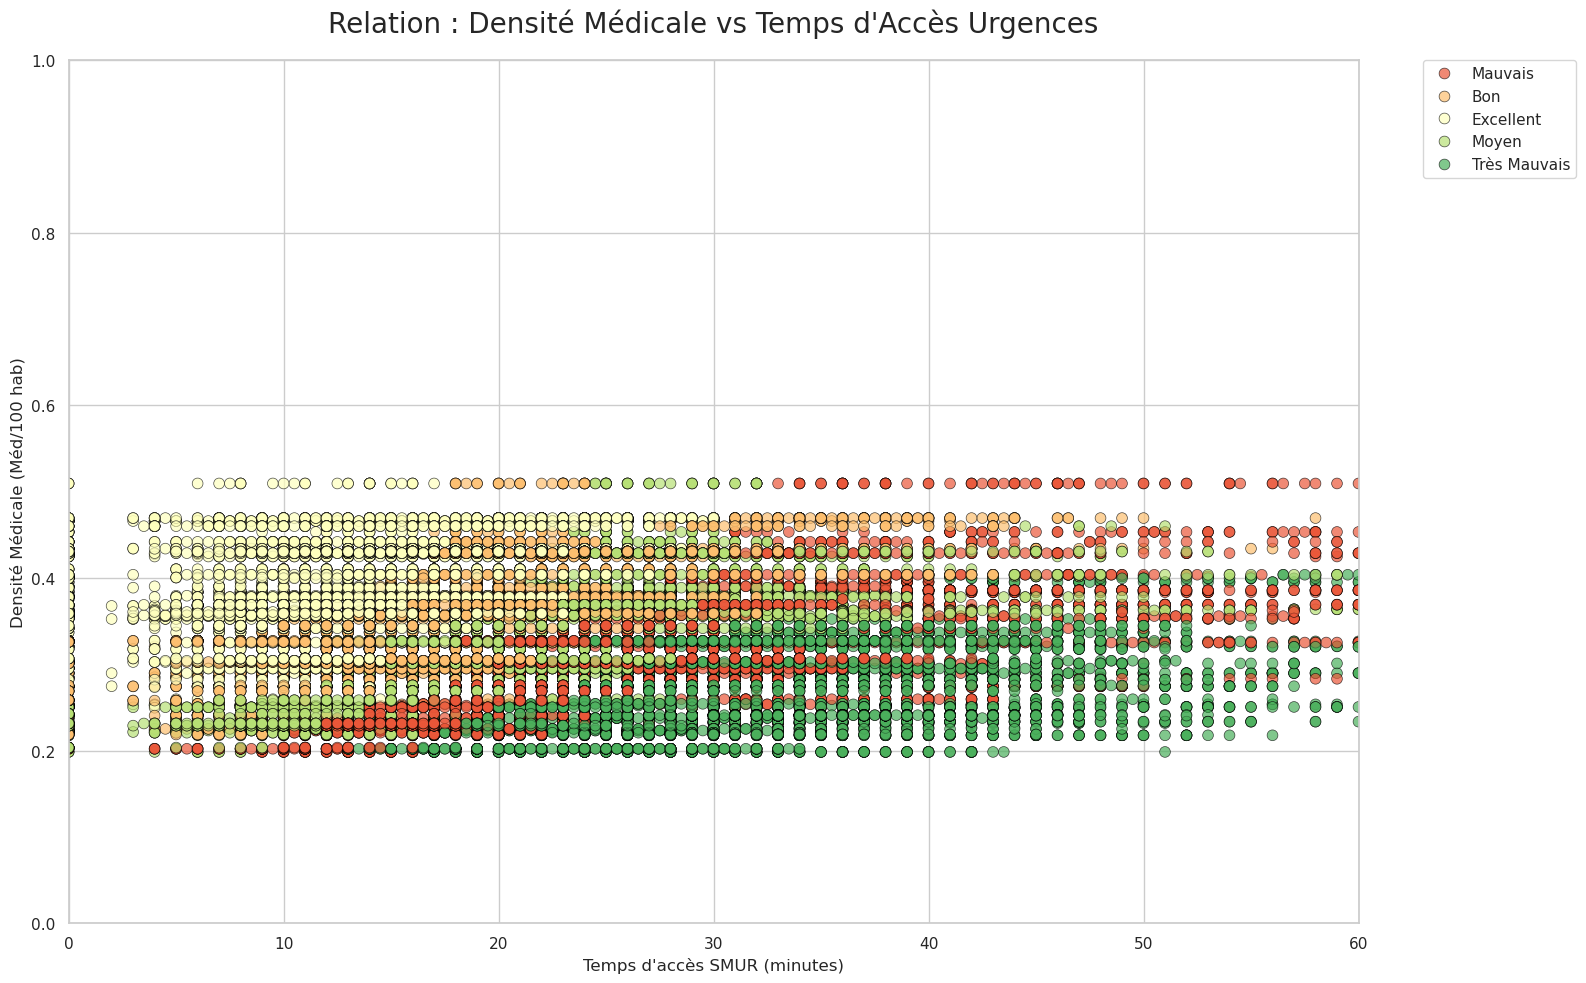

In [11]:
# 3. RELATIONS DENSITÉ / URGENCES (Scatter)
plt.figure(figsize=(16, 10))

sns.scatterplot(x='tps_smur', y='densite_med', hue='classe_acces', 
                data=df, palette='RdYlGn', alpha=0.7, s=60, edgecolor='black', linewidth=0.5)

plt.title("Relation : Densité Médicale vs Temps d'Accès Urgences", fontsize=20, pad=20)
plt.xlabel("Temps d'accès SMUR (minutes)")
plt.ylabel("Densité Médicale (Méd/100 hab)")
# On zoome sur la zone critique (0 à 1h de route)
plt.xlim(0, 60)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.) # Légende à l'extérieur
plt.tight_layout()
plt.show()

***Interprétation***

*Ce graphique compare la présence de médecins (axe vertical) et la distance aux urgences (axe horizontal) pour chaque commune.
Les points sont éparpillés, cela signifie qu'il n'y a pas de lien automatique entre les deux variables. Une ville peut avoir beaucoup de médecins mais être loin d'un hôpital, et inversement. Les deux ne vont pas forcément ensemble.
On peut aussi identifier la "barrière" des 30 minutes : le plus important est la couleur des points à droite du graphique. Dès qu'on dépasse 30 minutes de trajet pour les urgences, les points deviennent foncés (rouge ou vert), ce qui se traduit par un mauvais accès aux soins.
Donc, même si une commune a des médecins, si elle est trop loin des urgences (plus de 30 min), son score d'accès aux soins s'effondre. La proximité de l'hôpital est le critère décisif.*

#### 6.1.4. Matrice de corrélation

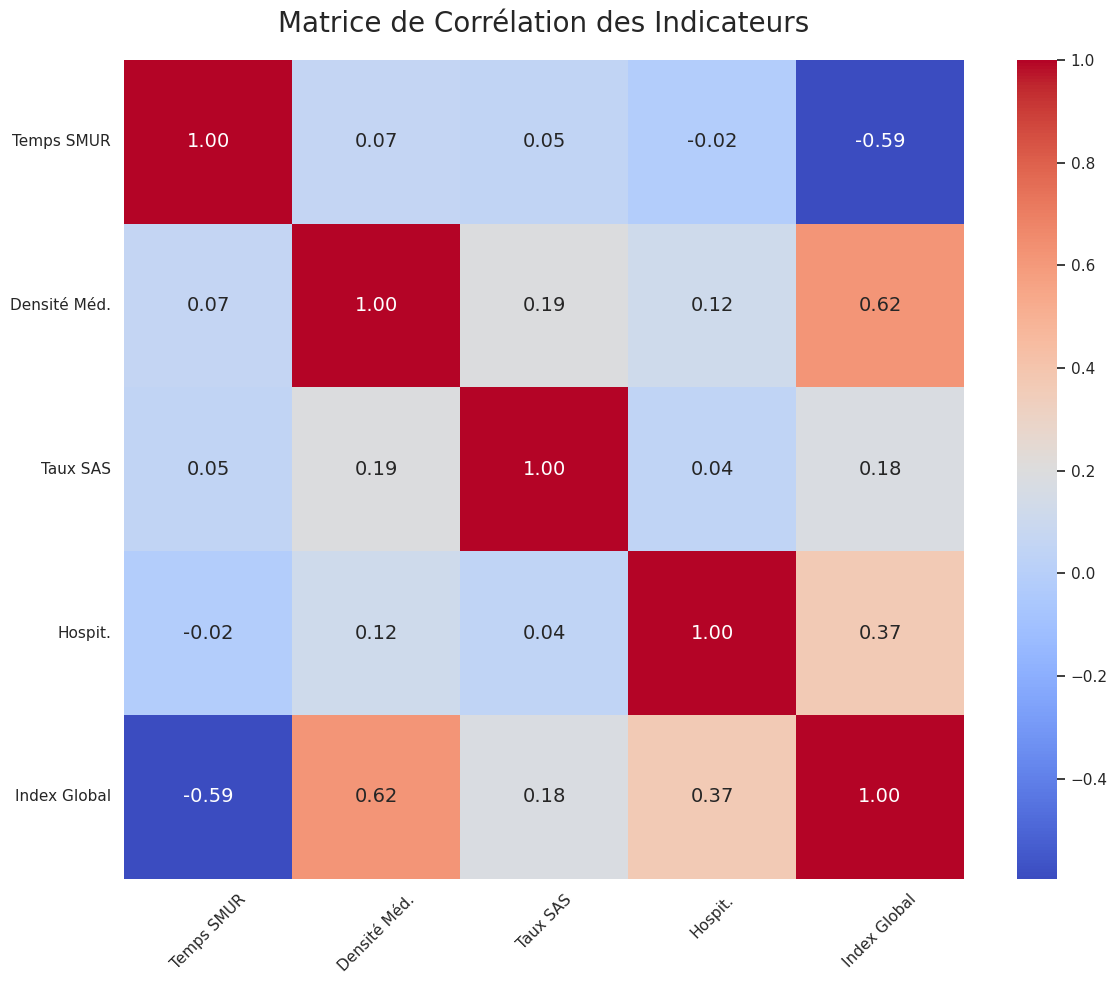

In [33]:
# Matrice de corrélation (Heatmap)
plt.figure(figsize=(12, 10))

corr_vars = ['tps_smur', 'densite_med', 'taux_sas', 'Hospitalisation', 'index_global']
# Renommage pour l'affichage propre
labels_clean = ['Temps SMUR', 'Densité Méd.', 'Taux SAS', 'Hospit.', 'Index Global']

heatmap = sns.heatmap(df[corr_vars].corr(), annot=True, cmap='coolwarm', 
                      fmt=".2f", annot_kws={"size": 14},
                      xticklabels=labels_clean, yticklabels=labels_clean)

plt.title("Matrice de Corrélation des Indicateurs", fontsize=20, pad=20)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

***Interprétation***

*Cette matrice de corrélation mesure l'intensité statistique des liens linéaires entre nos variables (sur une échelle de -1 à +1).
On observe de forts coefficients de corrélation entre l'Index Global et ses composantes (Temps SMUR et Densité). C'est attendu : cela confirme que notre index synthétise bien l'information contenue dans ces variables.
Certains coefficient sont proches de 0, cela signifie que les variables concernées sont indépendantes ou ont très peu de lien.  C'est notamment le cas pour le coefficient de corrélation entre le "Temps SMUR" et la "Densité Médicale" (le coefficient est quasi-nul).
En termes de science des données, on peut en déduidre que ces deux variables sont non-corrélées (linéairement indépendantes). On ne peut pas déduire la densité médicale d'une commune à partir de son temps d'accès aux urgences. Ce sont deux dimensions "orthogonales" du problème de l'accès aux soins.*

### 6.2. Cartographie interactive 

#### 6.2.1. Récupération des coordonnées géographiques

*Ce code géolocalise les données : il interroge l'API officielle geo.api.gouv.fr pour obtenir la latitude et la longitude de chaque commune à partir de son code INSEE. Il fusionne ensuite ces coordonnées avec notre dataset principal, ne conservant que les lignes complètes pour permettre la construction de la carte interactive.*

In [34]:
print("Récupération des coordonnées géographiques...")
url_api = 'https://geo.api.gouv.fr/communes?fields=code,centre&format=json&geometry=centre'

try:
    data = requests.get(url_api).json()
    geo = pd.json_normalize(data)
    geo['longitude'] = geo['centre.coordinates'].apply(lambda x: x[0] if isinstance(x, list) else None)
    geo['latitude'] = geo['centre.coordinates'].apply(lambda x: x[1] if isinstance(x, list) else None)
    geo = geo[['code', 'latitude', 'longitude']].rename(columns={'code': 'code_commune_insee'})

    df_geo = df.merge(geo, left_on='code_insee', right_on='code_commune_insee', how='inner')
    df_geo = df_geo.dropna(subset=['latitude', 'longitude', 'tps_smur'])
    print(f"Coordonnées récupérées pour {len(df_geo)} communes.")

except Exception as e:
    print(f"Erreur API Geo : {e}")
    df_geo = pd.DataFrame()

Récupération des coordonnées géographiques...
Coordonnées récupérées pour 34835 communes.


#### 6.2.2. Affichage de la carte des hôpitaux

In [11]:
import folium
import numpy as np

# Fonction de conversion Mercator -> Latitude/Longitude
def mercator_to_latlon(x, y):
    lon = (x / 20037508.34) * 180
    lat = (y / 20037508.34) * 180
    lat = 180 / np.pi * (2 * np.arctan(np.exp(lat * np.pi / 180)) - np.pi / 2)
    return lat, lon

# Vérification et calcul des coordonnées si nécessaire
if 'latitude' not in df_hosp.columns and 'y_mercator' in df_hosp.columns:
    print("Conversion des coordonnées Mercator en Latitude/Longitude...")
    df_hosp['latitude'], df_hosp['longitude'] = mercator_to_latlon(
        df_hosp['x_mercator'].values, 
        df_hosp['y_mercator'].values
    )

# Création de la carte
map_hosp = folium.Map(location=[46.603354, 1.888334], zoom_start=6)

# Ajout des marqueurs
for idx, row in df_hosp.iterrows():
    if not np.isnan(row['latitude']) and not np.isnan(row['longitude']):
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=3,
            color='darkblue',
            fill=True,
            fill_color='darkblue',
            fill_opacity=0.8,
            popup=f"Hôpital : {row.get('identifiant', idx)}"
        ).add_to(map_hosp)

map_hosp

Carte interactive enregistrée à part : carte_hopitaux.html


***Interprétation***

*Les points sont concentrés dans les zones urbaines et densément peuplées (grandes villes, régions littorales, axes majeurs), tandis que les zones rurales ou faiblement peuplées ont beaucoup moins de points. On observe donc un maillage hospitalier serré dans certains territoires et plus lâche dans d’autres, ce qui suggère des différences potentielles d’accessibilité aux soins hospitaliers.*

#### 6.2.3. Affichage de la carte de chaleur du temps d'accès aux soins

In [35]:
if not df_geo.empty:
    print("Génération de la carte...")
    m = folium.Map(location=[46.603354, 1.888334], zoom_start=6, tiles='cartodbpositron')

    # Couche Hôpitaux
    fg_hop = folium.FeatureGroup(name="Hôpitaux")
    cluster = MarkerCluster().add_to(fg_hop)
    for _, row in hop.iterrows():
        if pd.notna(row['latitude']) and pd.notna(row['longitude']):
            folium.Marker([row['latitude'], row['longitude']], popup=row['nom'],
                          icon=folium.Icon(color='blue', icon='plus', prefix='fa')).add_to(cluster)
    fg_hop.add_to(m)

    # Couche Heatmap Temps d'accès
    fg_heat = folium.FeatureGroup(name="Chaleur (Temps Accès)")
    heat_data = df_geo[['latitude', 'longitude', 'tps_smur']].values.tolist()
    HeatMap(heat_data, min_opacity=0.4, radius=15, blur=10,
            gradient={0.2: 'blue', 0.4: 'yellow', 0.6: 'orange', 1: 'red'}).add_to(fg_heat)
    fg_heat.add_to(m)

    folium.LayerControl(collapsed=False).add_to(m)
    m.save('carte_acces_soins.html')
    print("Carte sauvegardée : carte_acces_soins.html")
    display(m)
else:
    print("Pas de données géographiques pour la carte.")

Carte interactive enregistrée à part : carte_chaleur_acces.html


***Interprétation***

*Cette carte met en lumière une fracture territoriale majeure selon le lieu de résidence :*

1. *En France Métropolitaine : trois réalités distinctes*
- *La sécurité urbaine (Zones Vertes) : Les grandes agglomérations apparaissent comme des îlots privilégiés. La concentration des hôpitaux permet une intervention des secours en moins de 15 minutes.*
- *Le frein du relief (Zones Rouges) : Les massifs montagneux (Alpes, Pyrénées, Massif Central, Corse) constituent des barrières naturelles. Les routes sinueuses allongent mécaniquement les temps de trajet, créant des zones d'accès très lent.*
- *L'isolement rural (Zones Orange) : Une large bande transversale (du Nord-Est au Sud-Ouest) souffre d'un éloignement critique. Dans ces campagnes, le délai dépasse souvent le seuil de risque des 30 minutes, compromettant la prise en charge des urgences vitales.*

2. Outre-Mer (DROM-COM) : une polarisation extrême
- *Des contrastes importants: L'inégalité est encore plus marquée qu'en métropole. L'accès est excellent à proximité immédiate des CHU (Pointe-à-Pitre, Fort-de-France, Saint-Denis), mais s'effondre littéralement dès que l'on s'éloigne de quelques kilomètres vers l'intérieur des terres.*
- *La "Double Peine" : Aux distances s'ajoutent des contraintes géographiques très fortes (forêt amazonienne en Guyane, reliefs volcaniques à la Réunion ou aux Antilles). Certains territoires affichent alors des délais d'intervention bien supérieurs aux pires zones de métropole.*